In [1]:
##USE conda environment tf
# conda activate tf
import anndata as ad
import scanpy as sc
from matplotlib import rcParams
import pandas as pd
import h5py
import IPython
import bardensr.plotting
import numpy as np
import SimpleITK as sitk
import numpy as np
import tensorflow as tf
import bardensr.preprocessing
import harmonypy
import matplotlib.pyplot as plt


2026-07-25 16:23:36.451710: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-25 16:23:37.163493: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1785011017.427606 1465309 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1785011017.493119 1465309 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-07-25 16:23:38.251904: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

In [2]:
import numpy as np

def rotate_points(spatial, theta):
    # Define the rotation matrix
    rotation_matrix = np.array([
        [np.cos(theta), -np.sin(theta)],
        [np.sin(theta), np.cos(theta)]
    ])
    
    # Rotate the points
    rotated_points = spatial @ rotation_matrix.T
    
    return rotated_points

# Example usage
# Create a set of points (for example)
spatial = np.array([[1, 0], [0, 1], [-1, 0], [0, -1]])

# Define the rotation angle (in radians)
theta = np.pi / 4  # 45 degrees

# Rotate the points
rotated_spatial = rotate_points(spatial, theta)
print(rotated_spatial)

[[ 0.70710678  0.70710678]
 [-0.70710678  0.70710678]
 [-0.70710678 -0.70710678]
 [ 0.70710678 -0.70710678]]


In [3]:
def combine_and_rename_genes(adata, unwanted_genes):
    """
    Combine gene names with colons into their base names, summing duplicates,
    and filter out unwanted genes from the AnnData object.

    Parameters:
    adata: AnnData object containing gene expression data.
    unwanted_genes: List of gene names to exclude from the final result.

    Returns:
    AnnData object with updated gene names and filtered data.
    """
    gene_sums = {}
    # Iterate through the var_names to process them
    for var_name in adata.var_names:
        if ':' in var_name:
            # Get the base name before the colon
            base_name = var_name.split(':')[0]
            if base_name in gene_sums:
                # Sum the values for duplicates
                gene_sums[base_name] += adata[:, var_name].X
            else:
                # Initialize with the current values
                gene_sums[base_name] = adata[:, var_name].X
        else:
            # Copy over values for non-colon names
            if var_name not in gene_sums:
                gene_sums[var_name] = adata[:, var_name].X

    # Update var_names and the X values in the AnnData object
    new_var_names = list(gene_sums.keys())
    new_X = np.array(list(gene_sums.values()))
    print(new_X.shape)
    # Assign the updated names and values back to the AnnData object
    adata_new = ad.AnnData(new_X[:,:,0].T)
    adata_new.var_names = new_var_names
    adata_new.obs = adata.obs
    #adata_new.var = adata.var
    adata_new.obsm = adata.obsm

    #adata_new.var_names = new_var_names
    #adata_new.X = new_X

    # Filter out unwanted genes
    gene_list = [gene for gene in adata_new.var_names if gene not in unwanted_genes]
    adata_new = adata_new[:, gene_list]

    return adata_new

# Example usage:
# e11_sub = combine_and_rename_genes(e11_sub, ["Slc17a7", "Atf4", "Rex2", "Lamc1", "Sema3c", "Hoxd3", "Sox15", "Slit3"])

/tmp/ipykernel_1465309/2027675249.py:16: ImplicitModificationWarning: Setting element `.obsm['spatial3d']` of view, initializing view as actual.
  e11_1_corr.obsm['spatial3d'] = np.zeros([len(e11_1_corr),3])


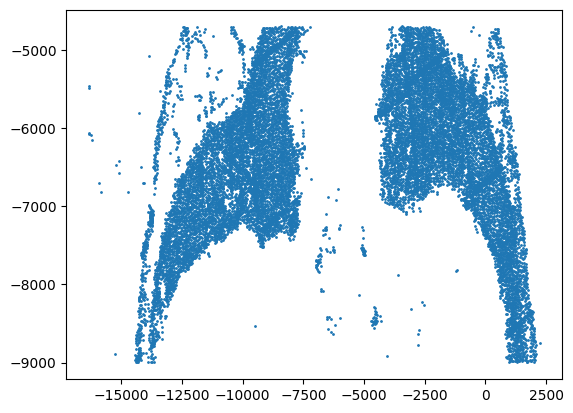

In [4]:
e11_1 = ad.read_h5ad("../../../mouse/e11/ma31_e11_a5/output/adata.h5ad")
e11_1.obs['library_id'] = 'e11_1'
e11_1.obs['timepoint'] = 'e11'
e11_1.obs['batch'] = 'batch2'

e11_1.obsm['spatial'] = rotate_points(e11_1.obsm['spatial'], (195/180)*3.14)
e11_1_coor = e11_1.obsm['spatial'][e11_1.obsm['spatial'][:,1] <-4700]
e11_1_coor = e11_1_coor[e11_1_coor[:,1] >-9000]
plt.scatter(e11_1_coor[:,0], e11_1_coor[:,1], s=1)

# Convert e13_1_coor to a list of tuples for faster lookups
e11_1_coor_set = {tuple(coord) for coord in e11_1_coor}
mask = np.array([tuple(coord) in e11_1_coor_set for coord in e11_1.obsm['spatial']])
e11_1_corr = e11_1[mask]

e11_1_corr.obsm['spatial3d'] = np.zeros([len(e11_1_corr),3])
x = e11_1_corr.obsm['spatial'][:,0]
y = e11_1_corr.obsm['spatial'][:,1]
e11_1_corr.obsm['spatial'][:,0] = (x - np.min(x))
e11_1_corr.obsm['spatial'][:,1] = (y - np.min(y))


/tmp/ipykernel_1465309/3441054985.py:16: ImplicitModificationWarning: Setting element `.obsm['spatial3d']` of view, initializing view as actual.
  e11_2_corr.obsm['spatial3d'] = np.zeros([len(e11_2_corr),3])


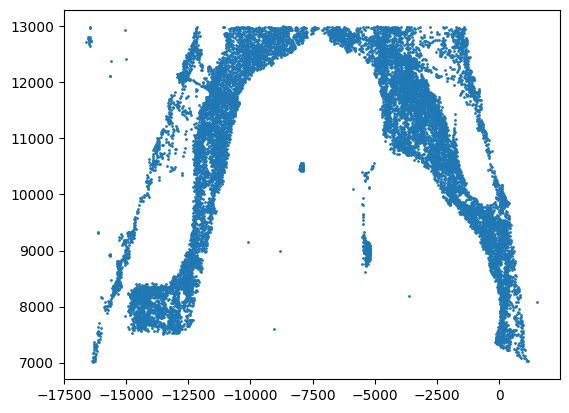

In [5]:
e11_2 = ad.read_h5ad("../../../mouse/e11/ma31_e11_b1/output/adata.h5ad")
e11_2.obs['library_id'] = 'e11_2'
e11_2.obs['timepoint'] = 'e11'
e11_2.obs['batch'] = 'batch2'

e11_2.obsm['spatial'] = rotate_points(e11_2.obsm['spatial'], (76/180)*3.14)
e11_2_coor = e11_2.obsm['spatial'][e11_2.obsm['spatial'][:,1] <13000]
e11_2_coor = e11_2_coor[e11_2_coor[:,1] >7000]
plt.scatter(e11_2_coor[:,0], e11_2_coor[:,1], s=1)

# Convert e13_1_coor to a list of tuples for faster lookups
e11_2_coor_set = {tuple(coord) for coord in e11_2_coor}
mask = np.array([tuple(coord) in e11_2_coor_set for coord in e11_2.obsm['spatial']])
e11_2_corr = e11_2[mask]

e11_2_corr.obsm['spatial3d'] = np.zeros([len(e11_2_corr),3])
x = e11_2_corr.obsm['spatial'][:,0]
y = e11_2_corr.obsm['spatial'][:,1]
e11_2_corr.obsm['spatial'][:,0] = (x - np.min(x))
e11_2_corr.obsm['spatial'][:,1] = (y - np.min(y))


/tmp/ipykernel_1465309/2654905048.py:16: ImplicitModificationWarning: Setting element `.obsm['spatial3d']` of view, initializing view as actual.
  e11_3_corr.obsm['spatial3d'] = np.zeros([len(e11_3_corr),3])


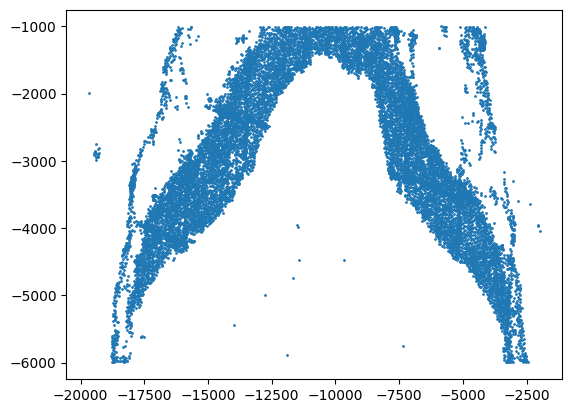

In [6]:
e11_3 = ad.read_h5ad("../../../mouse/e11/ma31_e11_b3/output/adata.h5ad")
e11_3.obs['library_id'] = 'e11_3'
e11_3.obs['timepoint'] = 'e11'
e11_3.obs['batch'] = 'batch2'

e11_3.obsm['spatial'] = rotate_points(e11_3.obsm['spatial'], (170/180)*3.14)
e11_3_coor = e11_3.obsm['spatial'][e11_3.obsm['spatial'][:,1] <-1000]
e11_3_coor = e11_3_coor[e11_3_coor[:,1] >-6000]
plt.scatter(e11_3_coor[:,0], e11_3_coor[:,1], s=1)

# Convert e13_1_coor to a list of tuples for faster lookups
e11_3_coor_set = {tuple(coord) for coord in e11_3_coor}
mask = np.array([tuple(coord) in e11_3_coor_set for coord in e11_3.obsm['spatial']])
e11_3_corr = e11_3[mask]

e11_3_corr.obsm['spatial3d'] = np.zeros([len(e11_3_corr),3])
x = e11_3_corr.obsm['spatial'][:,0]
y = e11_3_corr.obsm['spatial'][:,1]
e11_3_corr.obsm['spatial'][:,0] = (x - np.min(x))
e11_3_corr.obsm['spatial'][:,1] = (y - np.min(y))


/tmp/ipykernel_1465309/4014701626.py:16: ImplicitModificationWarning: Setting element `.obsm['spatial3d']` of view, initializing view as actual.
  e11_4_corr.obsm['spatial3d'] = np.zeros([len(e11_4_corr),3])


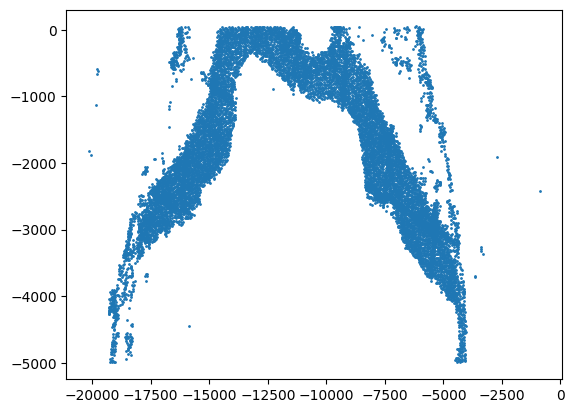

In [7]:
e11_4 = ad.read_h5ad("../../../mouse/e11/ma31_e11_c2/output/adata.h5ad")
e11_4.obs['library_id'] = 'e11_4'
e11_4.obs['timepoint'] = 'e11'
e11_4.obs['batch'] = 'batch2'

e11_4.obsm['spatial'] = rotate_points(e11_4.obsm['spatial'], (165/180)*3.14)
e11_4_coor = e11_4.obsm['spatial'][e11_4.obsm['spatial'][:,1] <50]
e11_4_coor = e11_4_coor[e11_4_coor[:,1] >-5000]
plt.scatter(e11_4_coor[:,0], e11_4_coor[:,1], s=1)

# Convert e13_1_coor to a list of tuples for faster lookups
e11_4_coor_set = {tuple(coord) for coord in e11_4_coor}
mask = np.array([tuple(coord) in e11_4_coor_set for coord in e11_4.obsm['spatial']])
e11_4_corr = e11_4[mask]

e11_4_corr.obsm['spatial3d'] = np.zeros([len(e11_4_corr),3])
x = e11_4_corr.obsm['spatial'][:,0]
y = e11_4_corr.obsm['spatial'][:,1]
e11_4_corr.obsm['spatial'][:,0] = (x - np.min(x))
e11_4_corr.obsm['spatial'][:,1] = (y - np.min(y))


In [8]:
adata = ad.concat([e11_1_corr, e11_2_corr, e11_3_corr, e11_4_corr])
adata.obs = adata.obs.reset_index(drop=True)


/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


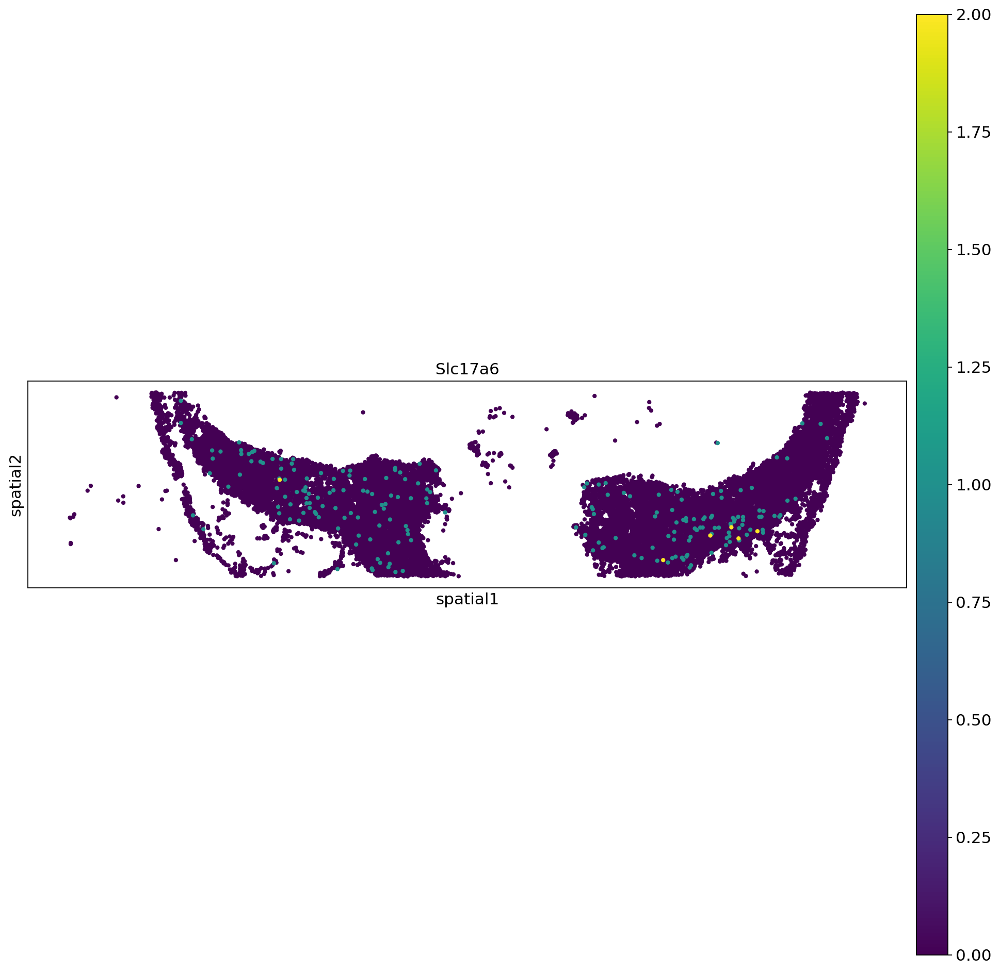

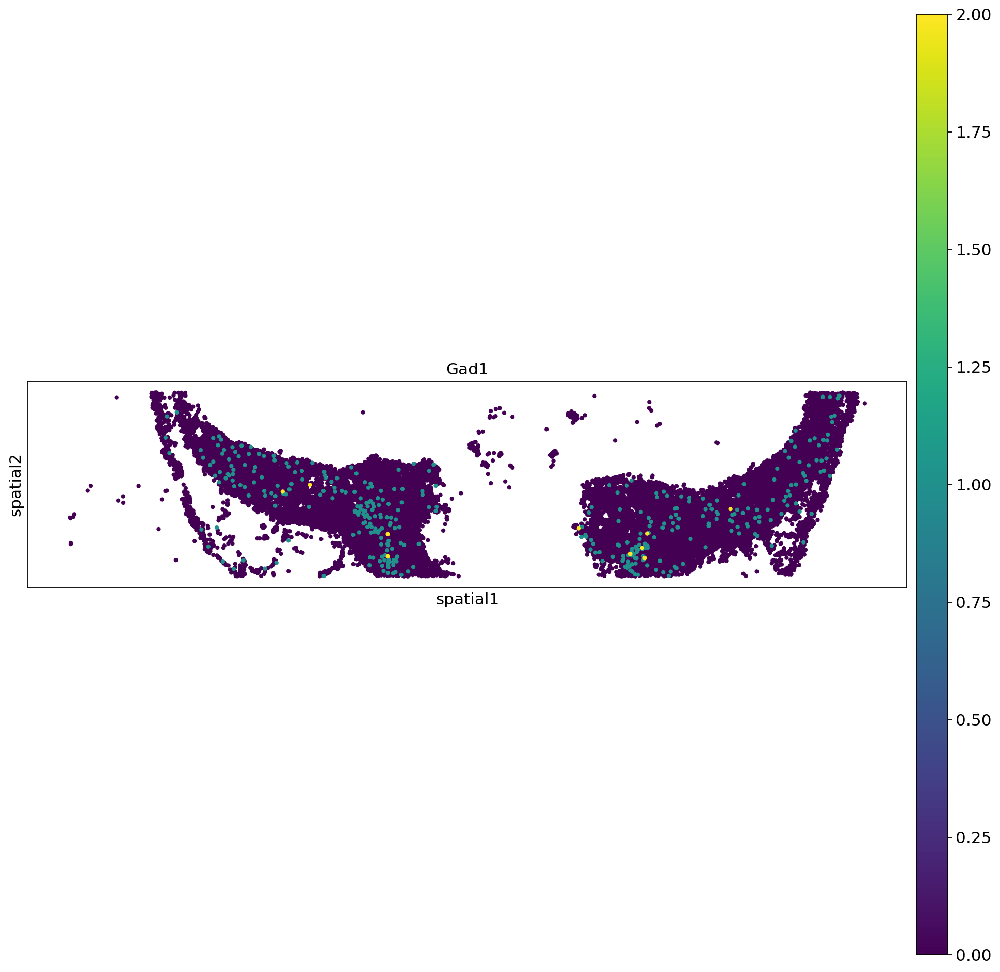

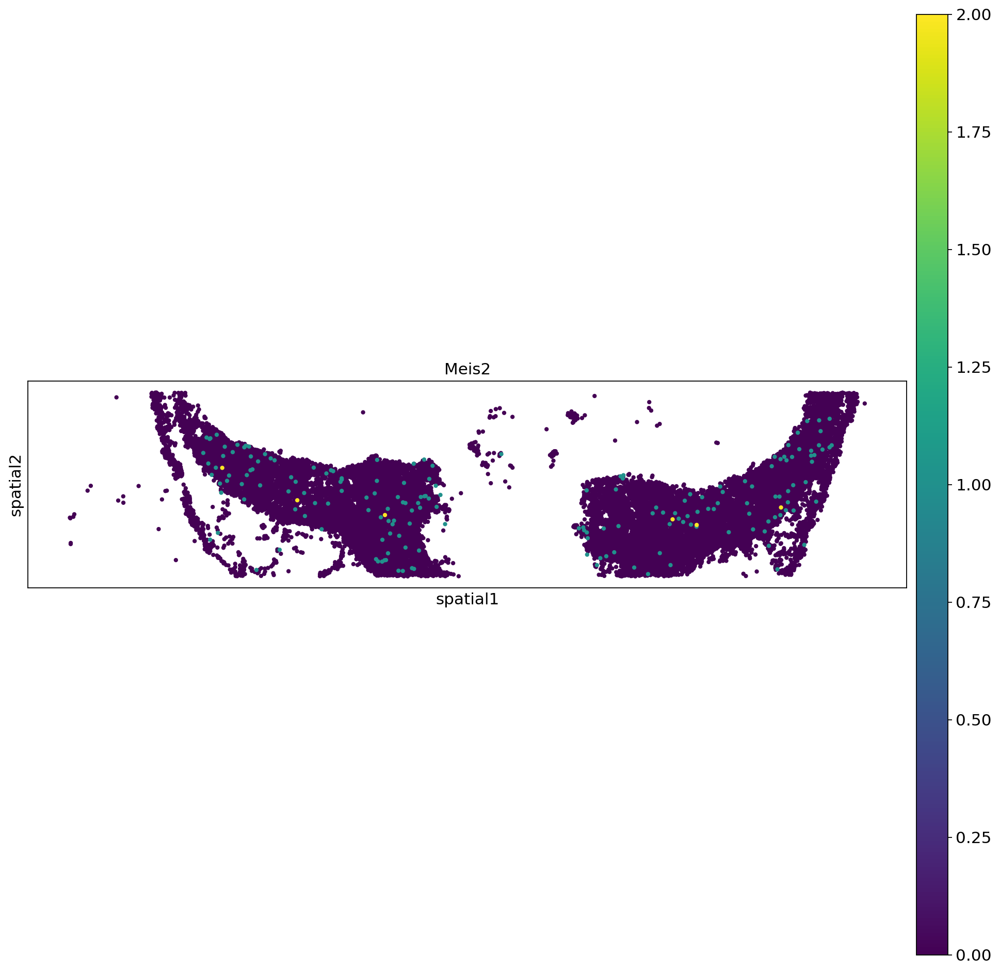

In [9]:
sc.set_figure_params(figsize = (15,15))
sc.pl.spatial(e11_1_corr, color = "Slc17a6", spot_size = 100, vmax = 2)
sc.pl.spatial(e11_1_corr, color = "Gad1", spot_size = 100, vmax = 2)
sc.pl.spatial(e11_1_corr, color = "Meis2", spot_size = 100, vmax = 2)

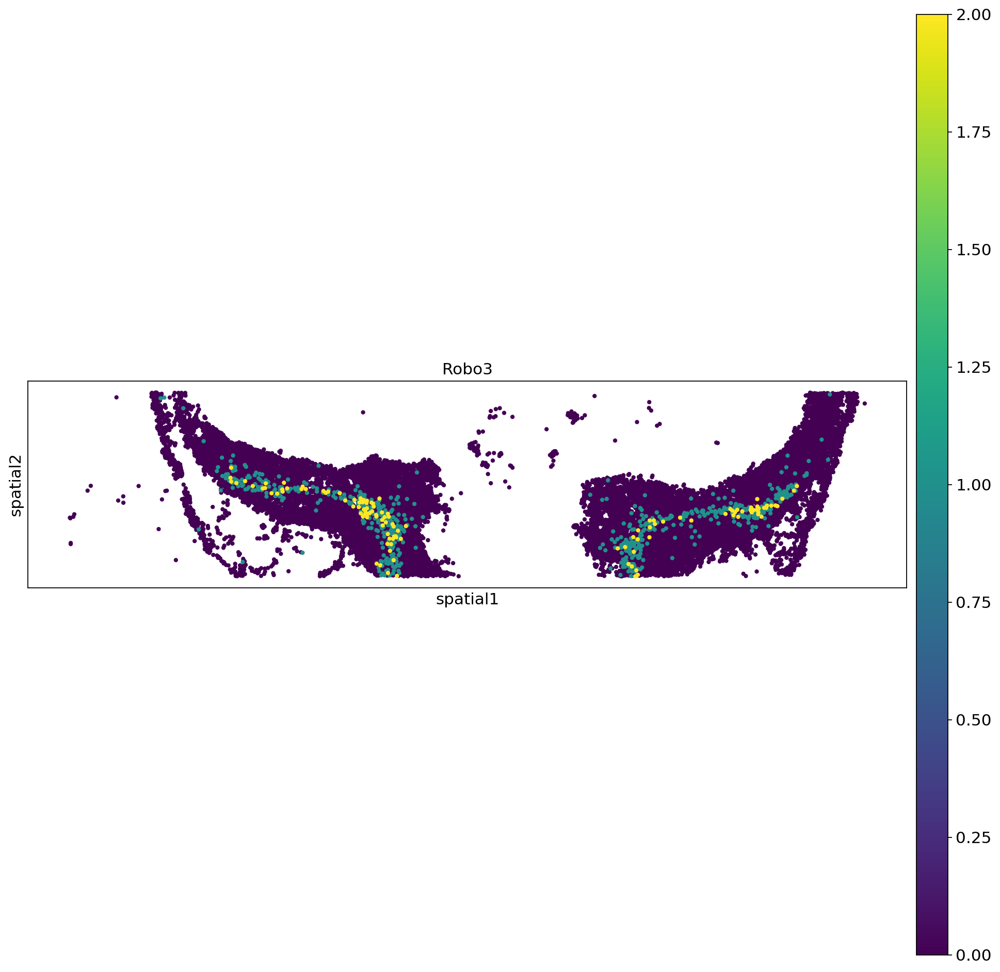

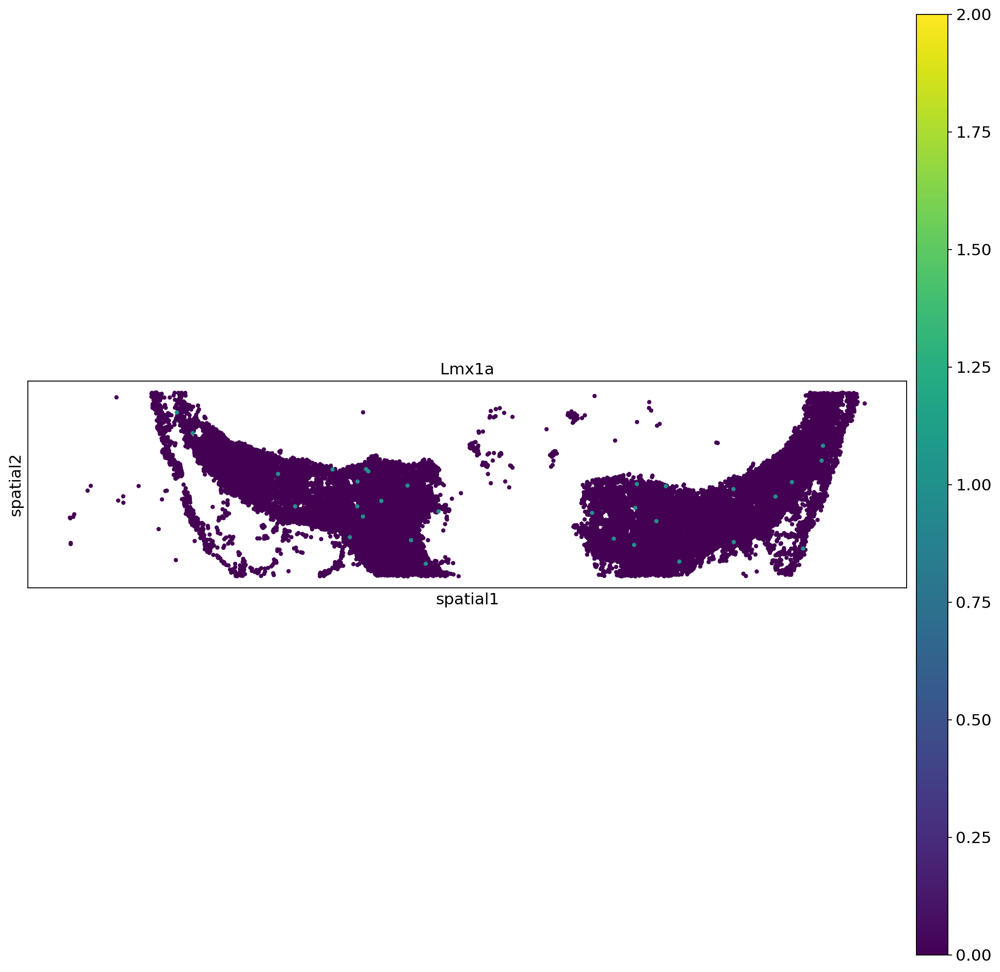

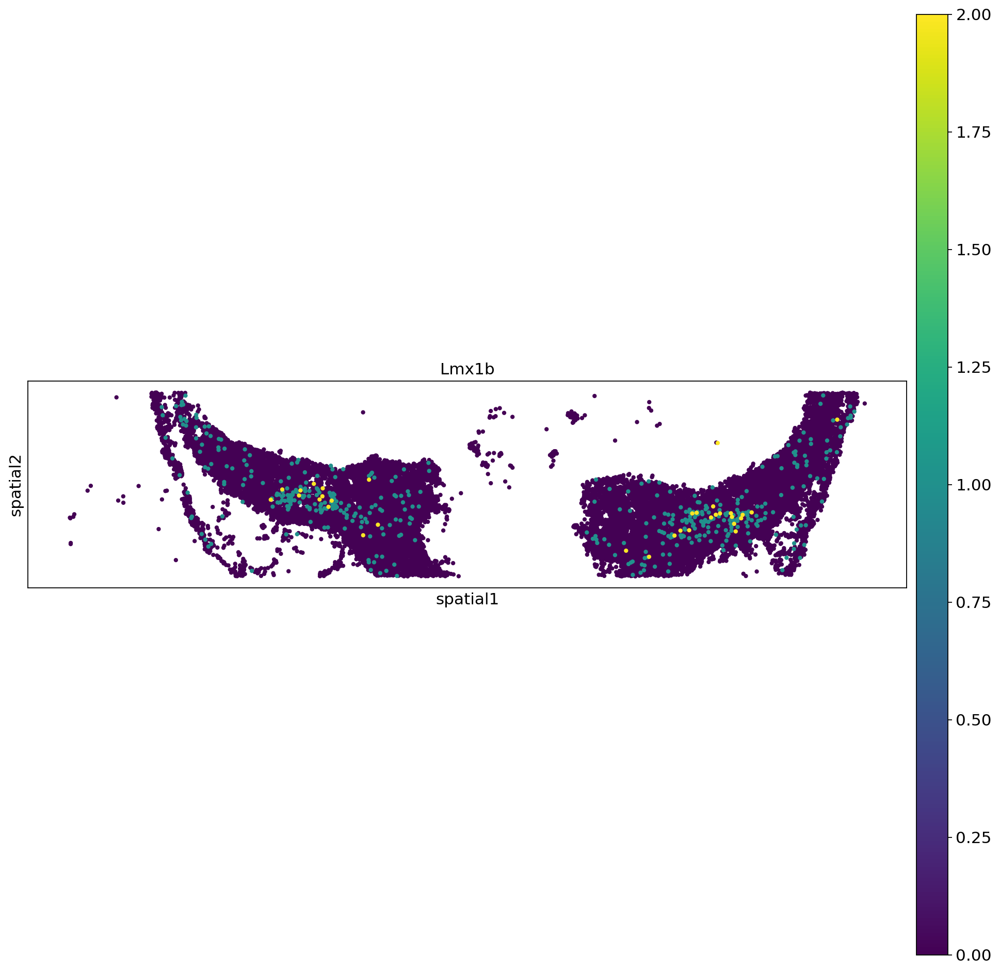

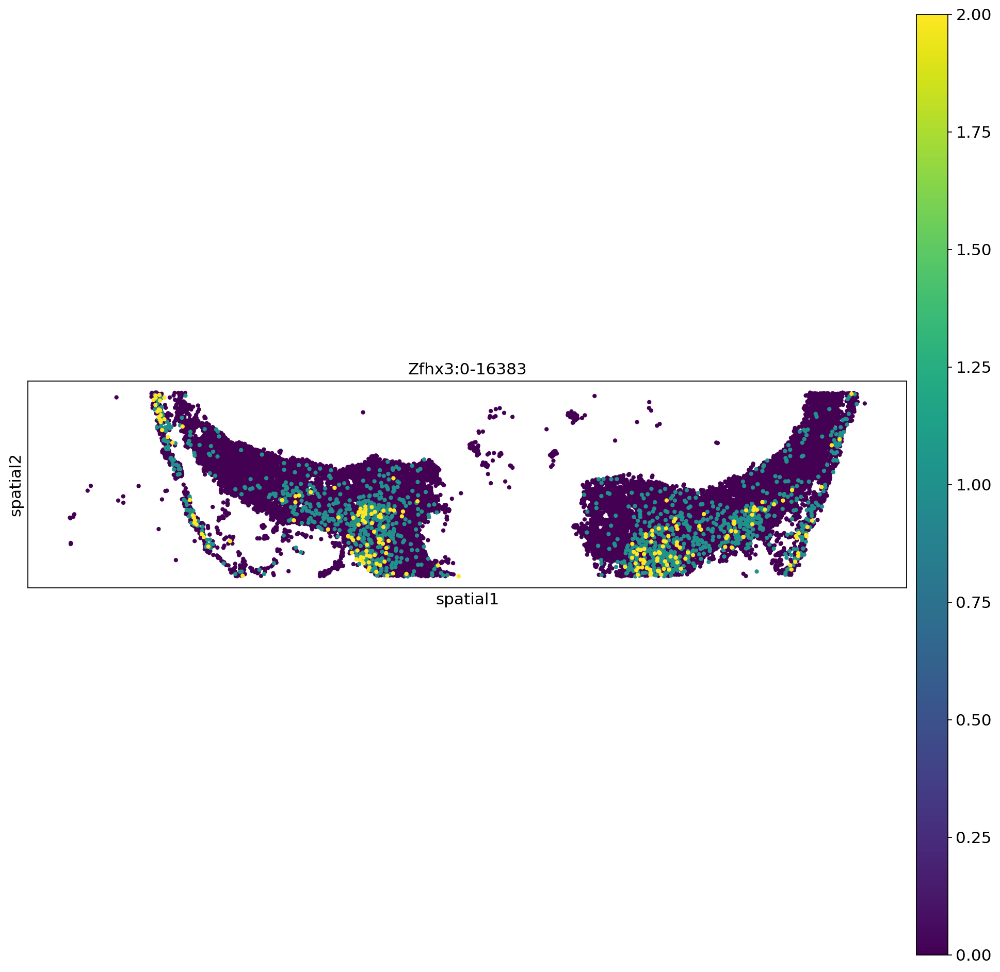

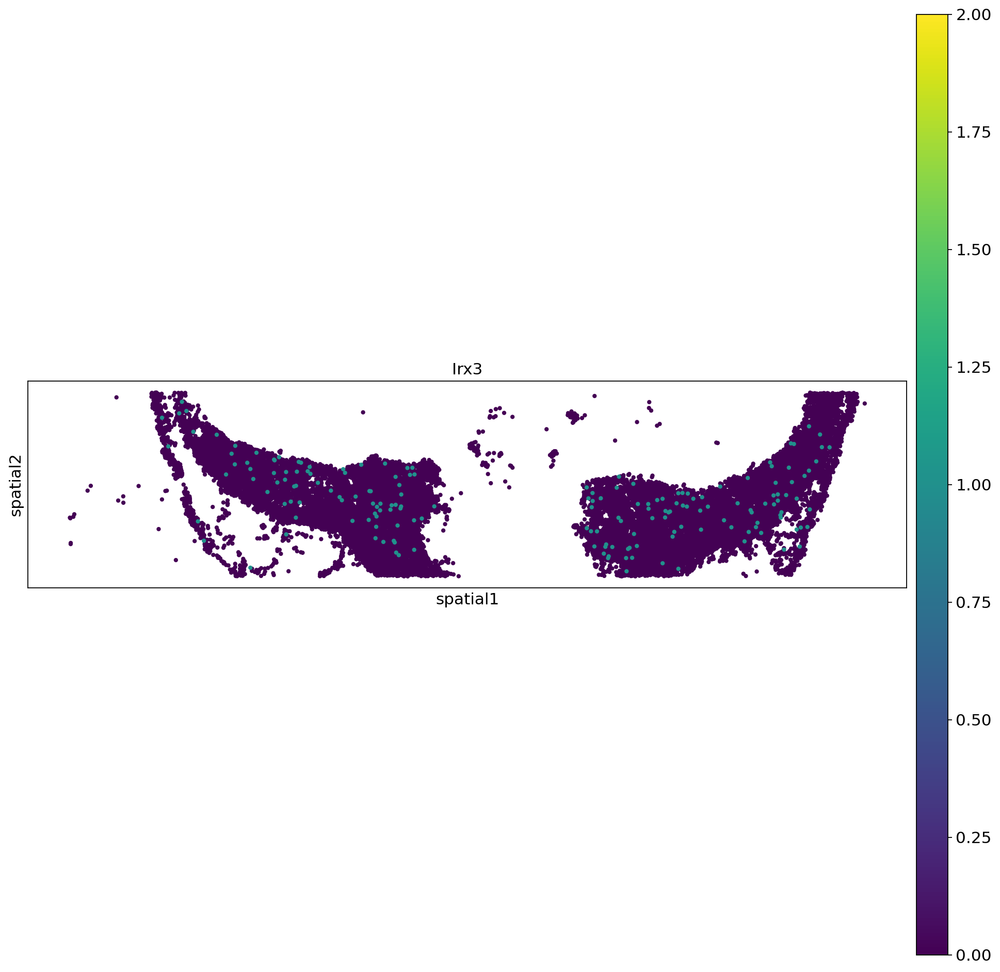

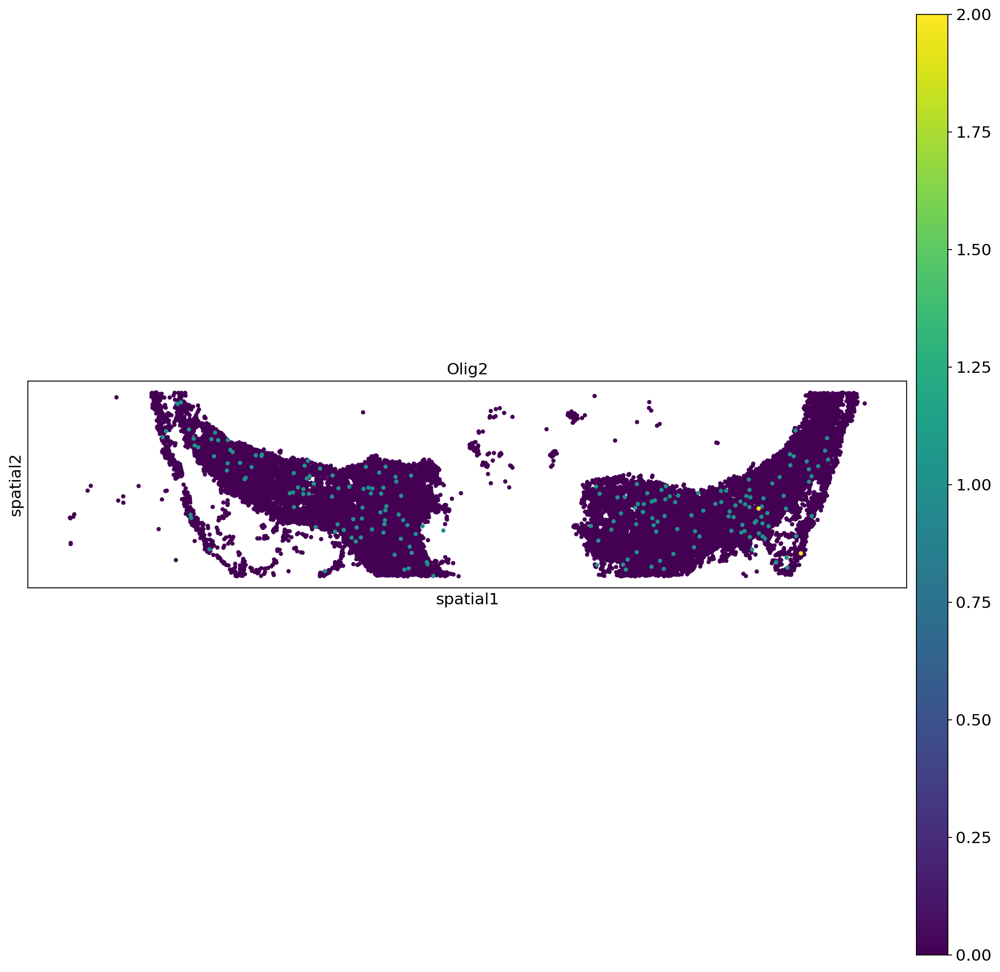

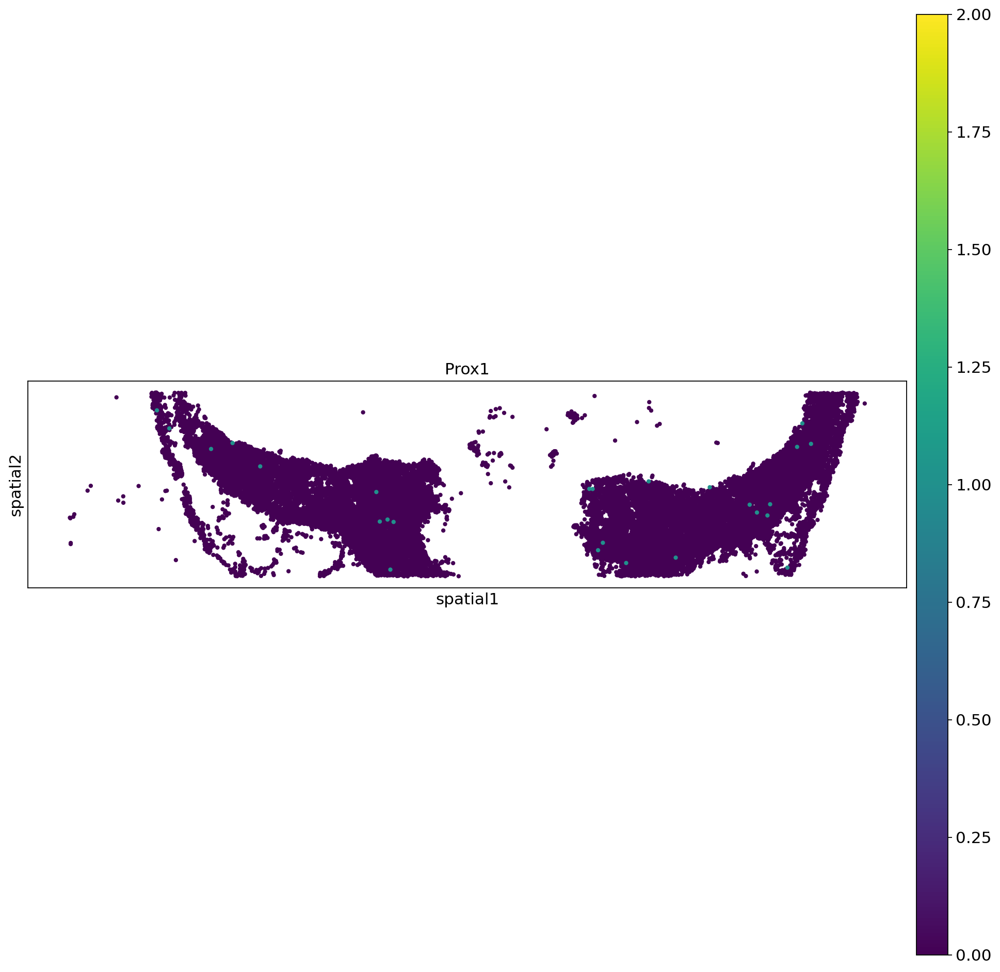

In [11]:
sc.set_figure_params(figsize = (15,15))
sc.pl.spatial(e11_1_corr, color = "Robo3", spot_size = 100, vmax = 2)
sc.pl.spatial(e11_1_corr, color = "Lmx1a", spot_size = 100, vmax = 2)
sc.pl.spatial(e11_1_corr, color = "Lmx1b", spot_size = 100, vmax = 2)
sc.pl.spatial(e11_1_corr, color = "Zfhx3:0-16383", spot_size = 100, vmax = 2)
sc.pl.spatial(e11_1_corr, color = "Irx3", spot_size = 100, vmax = 2)
sc.pl.spatial(e11_1_corr, color = "Olig2", spot_size = 100, vmax = 2)
sc.pl.spatial(e11_1_corr, color = "Prox1", spot_size = 100, vmax = 2)

In [9]:
adata.obsm['spatial'][:,1] = np.max(adata.obsm['spatial'][:,1])-adata.obsm['spatial'][:,1] 

In [10]:
import scanpy as sc
import numpy as np

# Assuming `adata` is your AnnData object
# Step 1: Identify genes that start with "Zfhx3"
genes_to_combine = [gene for gene in adata.var_names if gene.startswith("Zfhx3")]

if len(genes_to_combine) > 1:
    print(f"Found {len(genes_to_combine)} genes to combine: {genes_to_combine}")

    # Step 2: Select the first "Zfhx3" gene to keep
    first_gene = genes_to_combine[0]

    # Step 3: Add the counts of the other "Zfhx3" genes to the selected one
    for gene in genes_to_combine[1:]:
        # Add the counts from this gene to the first one
        adata[:, first_gene].X += adata[:, gene].X

    # Step 4: Rename the selected gene to "Zfhx3"
    adata.var_names = np.array([("Zfhx3" if gene == first_gene else gene) for gene in adata.var_names])

    # Step 5: Remove the other "Zfhx3" genes from the dataset
    adata = adata[:, ~adata.var_names.isin(genes_to_combine[1:])]  # Remove all but the first "Zfhx3" gene

    print(f"Gene '{first_gene}' combined with {len(genes_to_combine) - 1} other genes and renamed to 'Zfhx3'.")

else:
    print("No genes found starting with 'Zfhx3' or only one gene present.")

# After this, `adata` will have a single gene called "Zfhx3" combining the counts of the original genes.
# Assuming `adata` is your AnnData object

# Step 1: Find genes whose name contains 'no_gene'
gene_mask = adata.var_names.str.contains("no_gene")

# Step 2: Get the expression data for these genes
no_gene_counts = adata[:, gene_mask].X

# Step 3: Identify cells where any of the "no_gene" genes have counts > 1
cells_to_remove = np.any(no_gene_counts > 0, axis=1)

# Step 4: Remove those cells from the AnnData object
adata = adata[~cells_to_remove, :]

# Check the shape of the data after filtering
print(f"Data shape after filtering: {adata.shape}")

Found 2 genes to combine: ['Zfhx3:0-16383', 'Zfhx3:16384-17151']
Gene 'Zfhx3:0-16383' combined with 1 other genes and renamed to 'Zfhx3'.
Data shape after filtering: (44894, 1723)


In [9]:
sc.pp.calculate_qc_metrics(
    adata,percent_top=None, log1p=False, inplace=True
)
sc.pp.calculate_qc_metrics(
    adata,percent_top=None, log1p=False, inplace=True
)



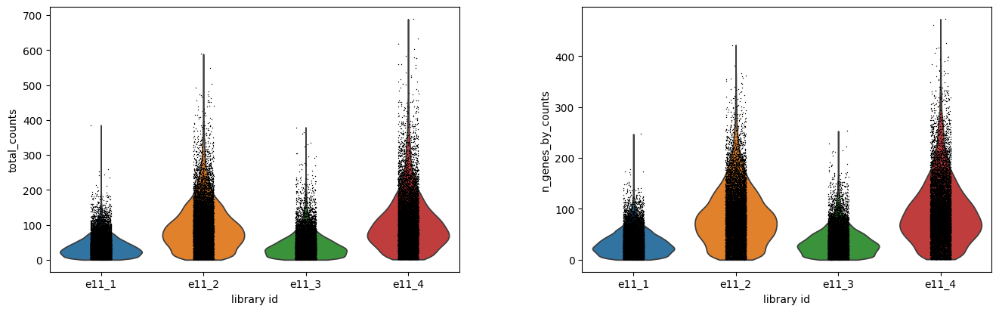

In [18]:
sc.pl.violin(adata, keys=["total_counts", "n_genes_by_counts"], groupby="library_id")

/tmp/ipykernel_2160604/934058898.py:15: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats = adata.obs.groupby('library_id').apply(lambda x: pd.Series({
/tmp/ipykernel_2160604/934058898.py:15: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  stats = adata.obs.groupby('library_id').apply(lambda x: pd.Series({


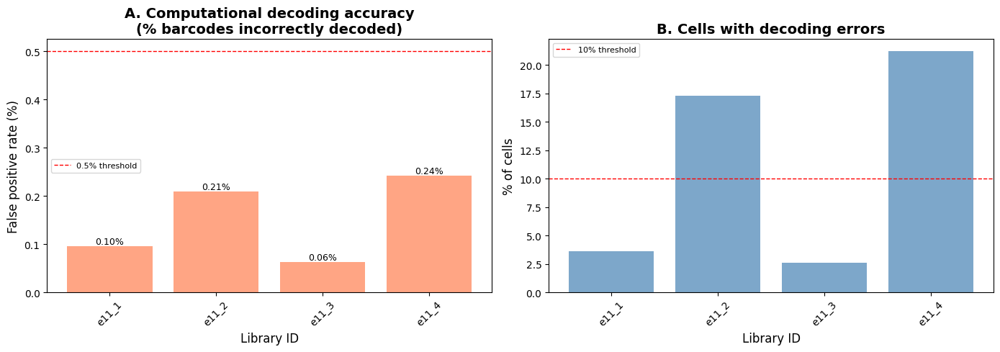


Computational decoding accuracy:
library_id  total_decoded_barcodes  false_positive_barcodes  false_positive_rate_pct  pct_cells_with_false_positives
     e11_1                573823.0                    547.0                 0.095326                        3.624675
     e11_2               1121298.0                   2347.0                 0.209311                       17.319729
     e11_3                543036.0                    337.0                 0.062059                        2.602230
     e11_4               1192730.0                   2887.0                 0.242050                       21.216710


In [23]:
import matplotlib.pyplot as plt
import pandas as pd

# Find all no_gene controls
no_gene_cols = [gene for gene in adata.var_names if 'no_gene' in gene.lower()]

if len(no_gene_cols) > 0:
    # Calculate false positive rate
    no_gene_total = adata[:, no_gene_cols].X.sum(axis=1)
    if hasattr(no_gene_total, 'A1'):
        no_gene_total = no_gene_total.A1
    adata.obs['no_gene_counts'] = no_gene_total
    
    # Metrics per library
    stats = adata.obs.groupby('library_id').apply(lambda x: pd.Series({
        'total_decoded_barcodes': x['total_counts'].sum(),
        'false_positive_barcodes': x['no_gene_counts'].sum(),
        'false_positive_rate_pct': x['no_gene_counts'].sum() / x['total_counts'].sum() * 100,
        'pct_cells_with_false_positives': (x['no_gene_counts'] > 0).sum() / len(x) * 100
    })).reset_index()
    
    # Plot
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Panel A: False positive rate (% of barcodes)
    axes[0].bar(stats['library_id'], stats['false_positive_rate_pct'], 
                color='coral', alpha=0.7)
    axes[0].axhline(0.5, color='red', linestyle='--', linewidth=1, 
                    label='0.5% threshold')
    axes[0].set_xlabel('Library ID', fontsize=12)
    axes[0].set_ylabel('False positive rate (%)', fontsize=12)
    axes[0].set_title('A. Computational decoding accuracy\n(% barcodes incorrectly decoded)', 
                      fontsize=14, fontweight='bold')
    axes[0].tick_params(axis='x', rotation=45)
    axes[0].legend(fontsize=8)
    
    # Add text annotations
    for i, row in stats.iterrows():
        axes[0].text(i, row['false_positive_rate_pct'], 
                    f"{row['false_positive_rate_pct']:.2f}%",
                    ha='center', va='bottom', fontsize=9)
    
    # Panel B: % cells affected
    axes[1].bar(stats['library_id'], stats['pct_cells_with_false_positives'], 
                color='steelblue', alpha=0.7)
    axes[1].axhline(10, color='red', linestyle='--', linewidth=1, 
                    label='10% threshold')
    axes[1].set_xlabel('Library ID', fontsize=12)
    axes[1].set_ylabel('% of cells', fontsize=12)
    axes[1].set_title('B. Cells with decoding errors', 
                      fontsize=14, fontweight='bold')
    axes[1].tick_params(axis='x', rotation=45)
    axes[1].legend(fontsize=8)
    
    plt.tight_layout()
    plt.savefig('figS2_decoding_accuracy.pdf', dpi=300, bbox_inches='tight')
    plt.show()
    
    print("\nComputational decoding accuracy:")
    print(stats.to_string(index=False))

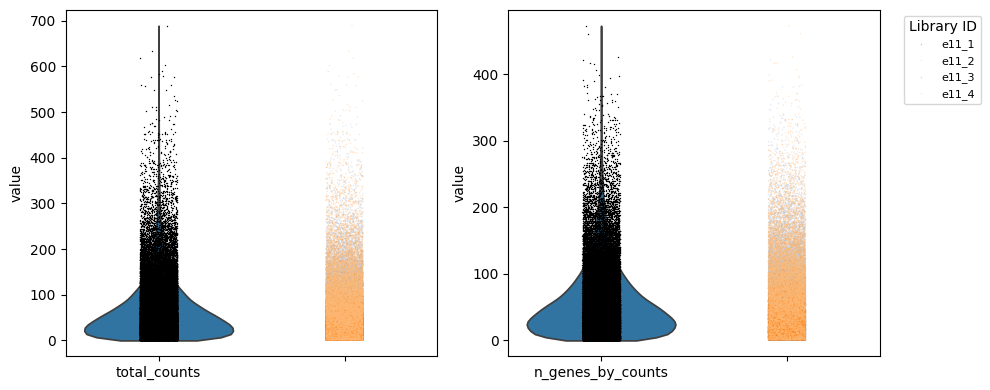

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 8), 
                         gridspec_kw={'height_ratios': [3, 1]})

# LEFT COLUMN - Total counts
# Top: Scatter
sns.scatterplot(data=adata.obs, x='library_id', y='total_counts', 
                hue='library_id', alpha=0.3, s=10, ax=axes[0, 0], 
                palette='tab20', linewidth=0, legend=False)
axes[0, 0].set_xlabel('')
axes[0, 0].set_ylabel('Total counts per cell', fontsize=12)
axes[0, 0].set_title('A. Total counts', fontsize=14, fontweight='bold')
axes[0, 0].tick_params(axis='x', labelbottom=False)

# Bottom: Box plot
sns.boxplot(data=adata.obs, x='library_id', y='total_counts', 
            ax=axes[1, 0], palette='tab20')
axes[1, 0].set_xlabel('Library ID', fontsize=12)
axes[1, 0].set_ylabel('Total counts', fontsize=12)
axes[1, 0].tick_params(axis='x', rotation=45)

# RIGHT COLUMN - Genes detected
# Top: Scatter
sns.scatterplot(data=adata.obs, x='library_id', y='n_genes_by_counts', 
                hue='library_id', alpha=0.3, s=10, ax=axes[0, 1], 
                palette='tab20', linewidth=0)
axes[0, 1].set_xlabel('')
axes[0, 1].set_ylabel('Genes detected per cell', fontsize=12)
axes[0, 1].set_title('B. Genes detected', fontsize=14, fontweight='bold')
axes[0, 1].tick_params(axis='x', labelbottom=False)
axes[0, 1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', 
                  fontsize=8, title='Library ID')

# Bottom: Box plot
sns.boxplot(data=adata.obs, x='library_id', y='n_genes_by_counts', 
            ax=axes[1, 1], palette='tab20')
axes[1, 1].set_xlabel('Library ID', fontsize=12)
axes[1, 1].set_ylabel('Genes detected', fontsize=12)
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.savefig('figS2_qc.pdf', dpi=300, bbox_inches='tight')
plt.show()

In [13]:
sc.pp.filter_cells(adata, min_counts=20)
sc.pp.filter_cells(adata, max_counts= 300)

sc.pp.filter_genes(adata, min_cells=10)


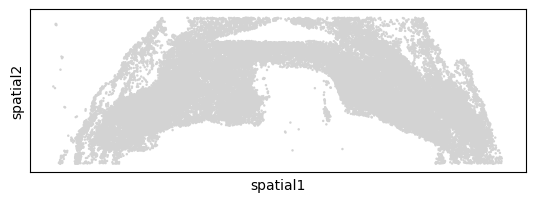

In [14]:
sc.pl.spatial(adata, spot_size = 100, vmax=2)

In [15]:
import scanpy as sc
import squidpy as sq
import scipy.sparse as sp

# --- Load your spatial AnnData ---
# Replace with your own dataset
#adata = sq.datasets.visium_hne_adata()


import scanpy as sc

print("save raw counts")
adata.layers["counts"] = adata.X.copy()

print("normalize total")
sc.pp.normalize_total(adata)
adata.layers["normalized"] = adata.X.copy()

print("log transform")
sc.pp.log1p(adata)
adata.layers["lognorm"] = adata.X.copy()   # use this for pseudobulk / correlations

print("highly_variable_genes")
# sc.pp.highly_variable_genes(adata, n_top_genes=500, batch_key="library_id")

print("regress_out")
sc.pp.regress_out(adata, ["total_counts"])
adata.layers["regressed"] = adata.X.copy()

print("scale")
sc.pp.scale(adata, max_value=10)
adata.layers["scaled"] = adata.X.copy()


# PCA for transcriptomic representation
sc.pp.pca(adata)
sc.external.pp.harmony_integrate(adata, 'library_id')


# --- Compute expression-based neighbors ---
sc.pp.neighbors(adata, use_rep="X_pca_harmony")#, n_neighbors=10)  # adjustable

# --- Compute spatial neighbors ---
adata.obsm['generic'] = adata.obsm['spatial']
sq.gr.spatial_neighbors(adata, coord_type="generic", radius=150)  # tune radius to your tissue size

# --- Create hybrid adjacency: weighted sum ---
expr_graph = adata.obsp['connectivities']
spatial_graph = adata.obsp['spatial_connectivities']



/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


save raw counts
normalize total
log transform
highly_variable_genes
regress_out
scale


2026-07-03 09:26:24,586 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-03 09:26:28,143 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-03 09:26:28,342 - harmonypy - INFO - Iteration 1 of 10
2026-07-03 09:26:37,377 - harmonypy - INFO - Iteration 2 of 10
2026-07-03 09:26:46,427 - harmonypy - INFO - Converged after 2 iterations


In [16]:
print("Leiden")

# --- Compute expression-based neighbors ---
sc.pp.neighbors(adata, use_rep="X_pca_harmony")#, n_neighbors=10)  # adjustable

# --- Compute spatial neighbors ---
adata.obsm['generic'] = adata.obsm['spatial']
sq.gr.spatial_neighbors(adata, coord_type="generic", radius=50)  # tune radius to your tissue size

# --- Create hybrid adjacency: weighted sum ---
expr_graph = adata.obsp['connectivities']
spatial_graph = adata.obsp['spatial_connectivities']

# Weight expression vs spatial influence
alpha = 0.95  # higher = more transcriptomic, lower = more spatial
hybrid_graph = expr_graph.multiply(alpha) + spatial_graph.multiply(1 - alpha)

# --- Cluster using hybrid graph ---
#sc.tl.leiden(adata, adjacency=hybrid_graph, key_added='hybrid_leiden', resolution=0.5)

# --- Visualization ---
sc.set_figure_params(figsize=(5, 5))
#sc.pl.umap(adata, color=["hybrid_leiden", "library_id", "batch"], size=5)

Leiden


In [17]:
sc.tl.leiden(adata, adjacency=hybrid_graph, key_added='hybrid_leiden', resolution=1.5)


/tmp/ipykernel_3564757/4162622865.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, adjacency=hybrid_graph, key_added='hybrid_leiden', resolution=1.5)


/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


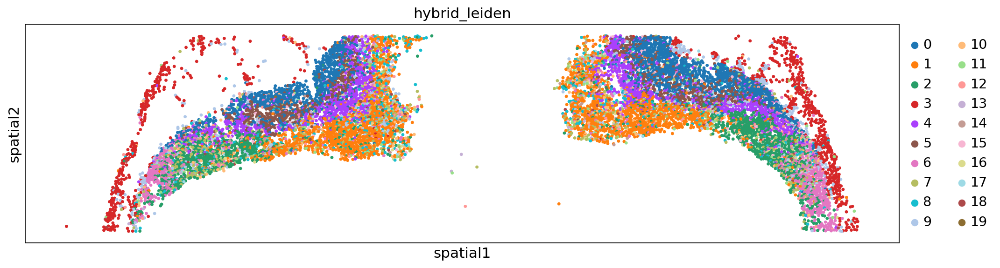

/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


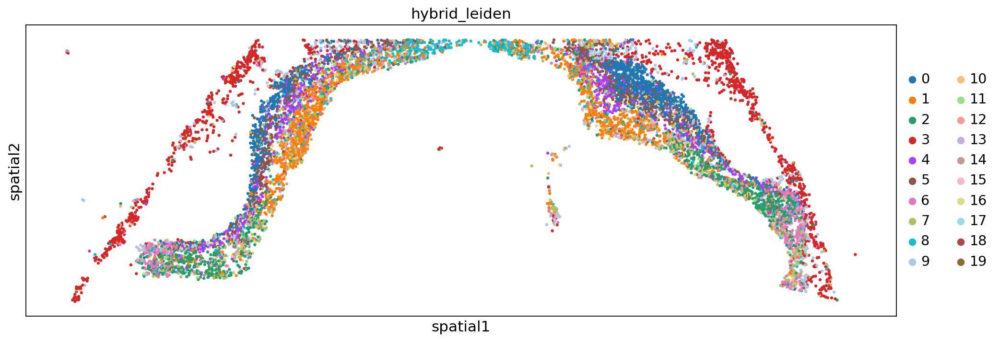

/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


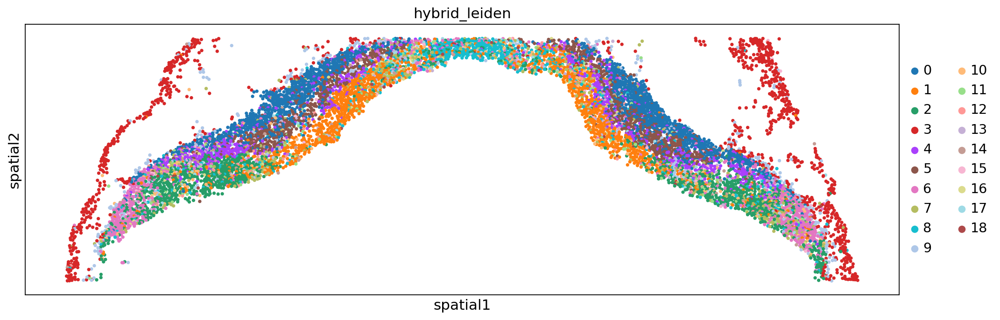

/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/plotting/_utils.py:487: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + "_colors"] = colors_list


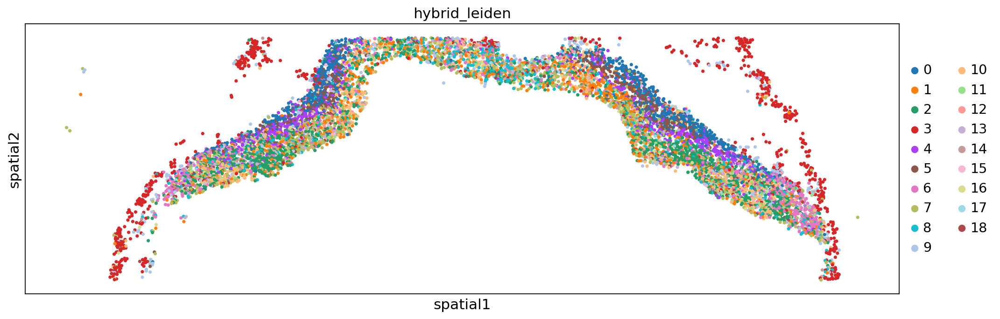

In [18]:
sc.set_figure_params(figsize=(15, 5))
for i in np.unique(adata.obs['library_id']):
    sc.pl.spatial(adata[adata.obs['library_id']==i], color='hybrid_leiden', spot_size = 70, vmax=2)

/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.l

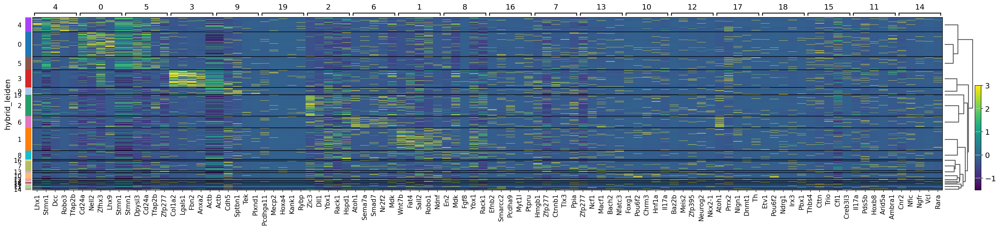

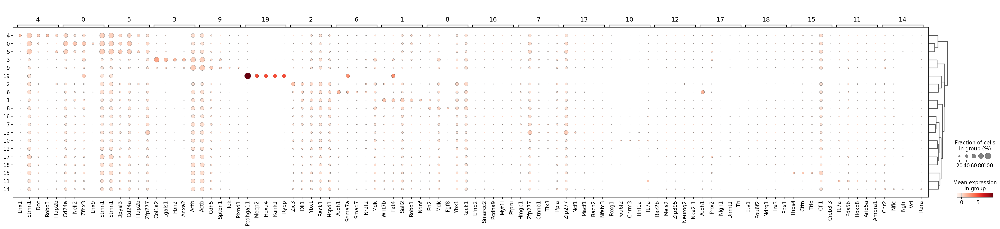

In [28]:
sc.tl.dendrogram(adata, groupby="hybrid_leiden")
sc.tl.rank_genes_groups(adata, 'hybrid_leiden', method='wilcoxon', key_added = "wilcoxon")
sc.pl.rank_genes_groups_heatmap(adata, n_genes=5, key="wilcoxon", groupby="hybrid_leiden", show_gene_labels=True, vmax = 3)
sc.pl.rank_genes_groups_dotplot(adata, n_genes=5, key="wilcoxon", groupby="hybrid_leiden")

In [19]:
label_clusters = {
    "0": "DCN",
    "1": "Med_Prog",
    "2": "Lat_Prog",
    "3": "Outside_Cb",
    "4": "Inhib_Prog",
    "5": "Inhib_Prog2",
    "6": "RL",
    "7": "Prog_General",
    "8": "Isthmus",
    "9": "Glia",
    }

adata.obs["cell_types"] = adata.obs['hybrid_leiden'].map(label_clusters)
adata.obs["finer_cell_types"] = adata.obs['hybrid_leiden'].map(label_clusters)

In [20]:
adata_crop = adata[adata.obs['hybrid_leiden'].isin(['0'])]

In [21]:
# PCA for transcriptomic representation
#sc.pp.pca(adata_crop)

#sc.external.pp.harmony_integrate(adata_crop, 'library_id', theta = 0.4)


# --- Compute expression-based neighbors ---
sc.pp.neighbors(adata_crop, use_rep="X_pca_harmony")#, n_neighbors=10)  # adjustable

# --- Compute spatial neighbors ---
adata_crop.obsm['generic'] = adata_crop.obsm['spatial']
sq.gr.spatial_neighbors(adata_crop, coord_type="generic", radius=50)  # tune radius to your tissue size

# --- Create hybrid adjacency: weighted sum ---
expr_graph = adata_crop.obsp['connectivities']
spatial_graph = adata_crop.obsp['spatial_connectivities']

# Weight expression vs spatial influence
alpha = 0.8  # higher = more transcriptomic, lower = more spatial
hybrid_graph = expr_graph.multiply(alpha) + spatial_graph.multiply(1 - alpha)

# --- Cluster using hybrid graph ---
sc.tl.leiden(adata_crop, adjacency=hybrid_graph, key_added='hybrid_leiden', resolution=0.4)



In [22]:
sq.gr.spatial_neighbors(adata_crop, coord_type="generic", radius=50)  # tune radius to your tissue size

# --- Create hybrid adjacency: weighted sum ---
expr_graph = adata_crop.obsp['connectivities']
spatial_graph = adata_crop.obsp['spatial_connectivities']

# Weight expression vs spatial influence
alpha = 0.9  # higher = more transcriptomic, lower = more spatial
hybrid_graph = expr_graph.multiply(alpha) + spatial_graph.multiply(1 - alpha)

# --- Cluster using hybrid graph ---
sc.tl.leiden(adata_crop, adjacency=hybrid_graph, key_added='hybrid_leiden', resolution=0.8)

/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


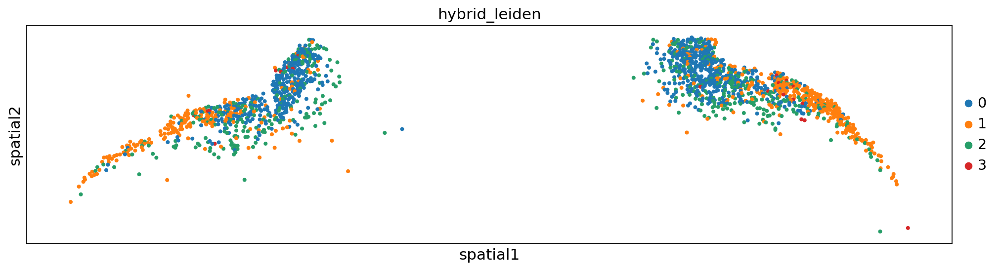

/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


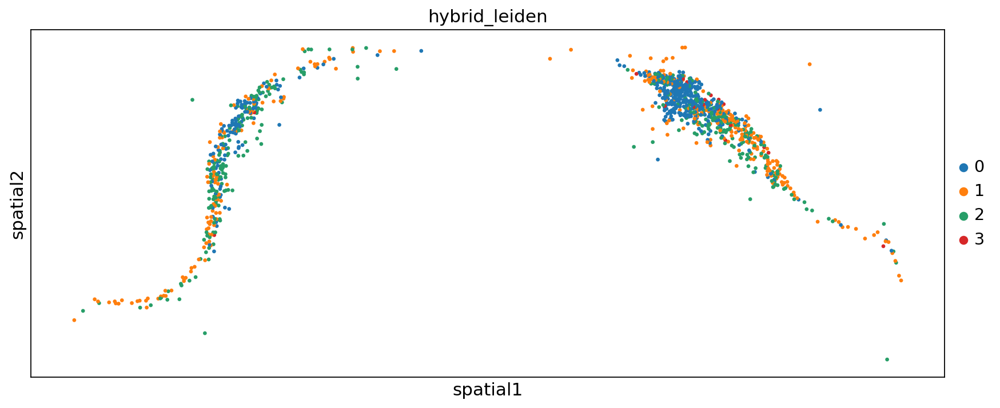

/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


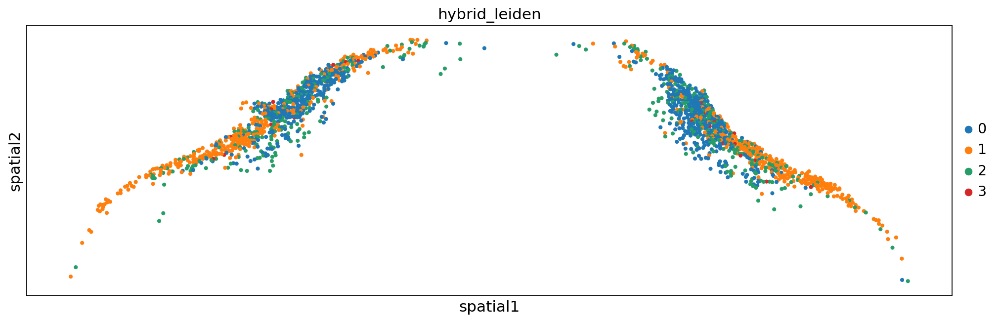

/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/anndata/_core/anndata.py:1145: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


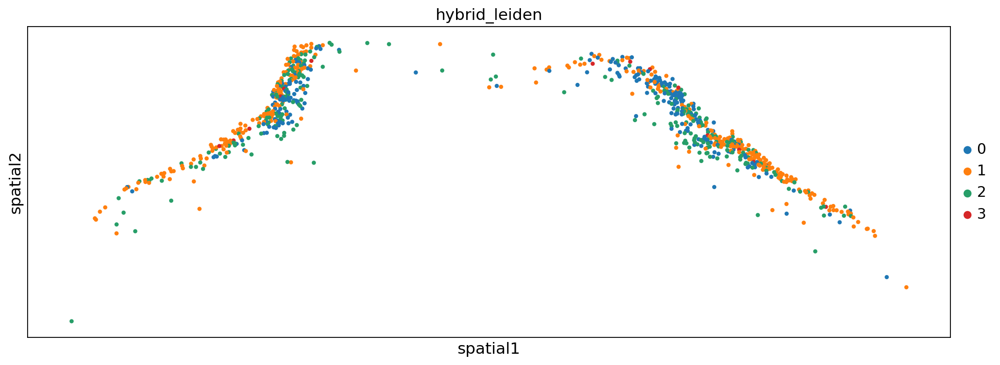

In [23]:
sc.set_figure_params(figsize=(15, 5))
for i in np.unique(adata_crop.obs['library_id']):
    sc.pl.spatial(adata_crop[adata_crop.obs['library_id']==i], color='hybrid_leiden', spot_size = 70, vmax=2)
    #sc.pl.spatial(adata_crop[adata_crop.obs['library_id']==i], color='Robo2', spot_size = 70, vmax=2)
    #sc.pl.spatial(adata_crop[adata_crop.obs['library_id']==i], color='Ret', spot_size = 70, vmax=2)#

/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(


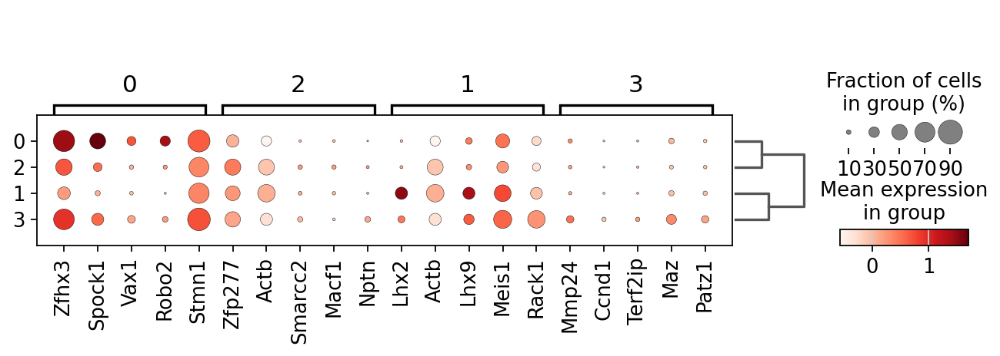

In [24]:
sc.tl.dendrogram(adata_crop, groupby="hybrid_leiden")
sc.tl.rank_genes_groups(adata_crop, 'hybrid_leiden', method='wilcoxon', key_added = "wilcoxon")
#sc.pl.rank_genes_groups_heatmap(adata_crop, n_genes=5, key="wilcoxon", groupby="hybrid_leiden", show_gene_labels=True, vmax = 3)
sc.pl.rank_genes_groups_dotplot(adata_crop, n_genes=5, key="wilcoxon", groupby="hybrid_leiden")

In [25]:
label_clusters = {
    "0": "DCN1",
    "1": "DCN2",
    "2": "DCN3",
    
    }

adata_crop.obs["cell_types"] = adata_crop.obs['hybrid_leiden'].map(label_clusters)
adata_crop.obs["finer_cell_types"] = adata_crop.obs['hybrid_leiden'].map(label_clusters)

/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(
/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/tools/_rank_genes_groups.py:461: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(


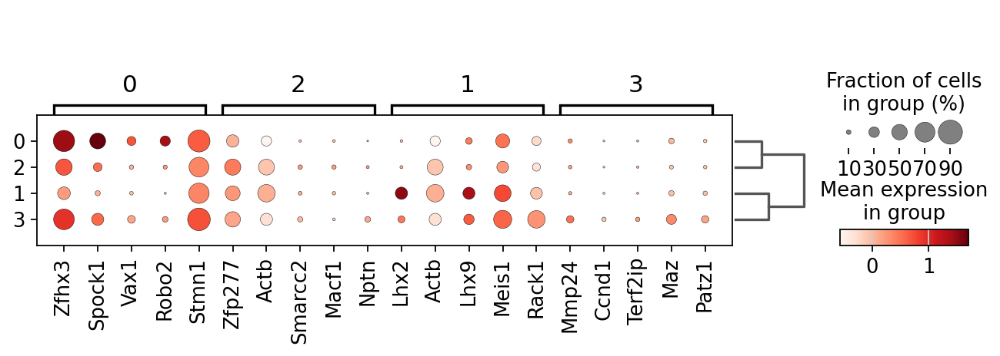

In [26]:
sc.tl.dendrogram(adata_crop, groupby="hybrid_leiden")
sc.tl.rank_genes_groups(adata_crop, 'hybrid_leiden', method='wilcoxon', key_added = "wilcoxon")
#sc.pl.rank_genes_groups_heatmap(adata_crop, n_genes=5, key="wilcoxon", groupby="cell_types", show_gene_labels=True)
sc.pl.rank_genes_groups_dotplot(adata_crop, n_genes=5, key="wilcoxon", groupby="hybrid_leiden")

## Label clusters and combine

In [27]:
import scanpy as sc

# Ensure indices are unique before merging

adata_crop.obs.index = adata_crop.obs.index.astype(str)
adata.obs.index = adata.obs.index.astype(str)

# Merge "finer_cell_types" into "cell_types" where available
if "finer_cell_types" in adata_crop.obs.columns:
    adata_crop.obs["cell_types"] = adata_crop.obs.get("cell_types", adata_crop.obs["finer_cell_types"])

    
# Concatenate on cell number (index)
adata_all = sc.concat([adata_crop, adata], join="outer", merge="first")

# Remove duplicate cell indices, keeping the first occurrence
adata_all = adata_all[~adata_all.obs.index.duplicated(keep='first')]

# Remove cells with missing or "NA" cell type labels
adata_all = adata_all[adata_all.obs['cell_types'].notna() & (adata_all.obs['cell_types'] != "NA")]
adata_all = adata_all[adata_all.obs['finer_cell_types'].notna() & (adata_all.obs['finer_cell_types'] != "NA")]

# Print summary
print(adata_all)


View of AnnData object with n_obs × n_vars = 30531 × 1716
    obs: 'cell_number', 'library_id', 'timepoint', 'batch', 'n_genes_by_counts', 'total_counts', 'n_counts', 'hybrid_leiden', 'cell_types', 'finer_cell_types'
    var: 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'mean', 'std'
    obsm: 'spatial', 'spatial3d', 'X_pca', 'X_pca_harmony', 'generic'
    varm: 'PCs'
    layers: 'counts', 'normalized', 'lognorm', 'regressed', 'scaled'


/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/anndata/_core/anndata.py:1754: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.
  utils.warn_names_duplicates("obs")


PCA


/home/manant1/.conda/envs/tf/lib/python3.9/site-packages/scanpy/preprocessing/_pca.py:317: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = X_pca
2026-07-03 09:34:45,096 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-07-03 09:34:48,145 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-07-03 09:34:48,283 - harmonypy - INFO - Iteration 1 of 10
2026-07-03 09:34:54,483 - harmonypy - INFO - Iteration 2 of 10
2026-07-03 09:35:00,734 - harmonypy - INFO - Iteration 3 of 10
2026-07-03 09:35:03,243 - harmonypy - INFO - Iteration 4 of 10
2026-07-03 09:35:05,474 - harmonypy - INFO - Converged after 4 iterations


neighbors
UMAP


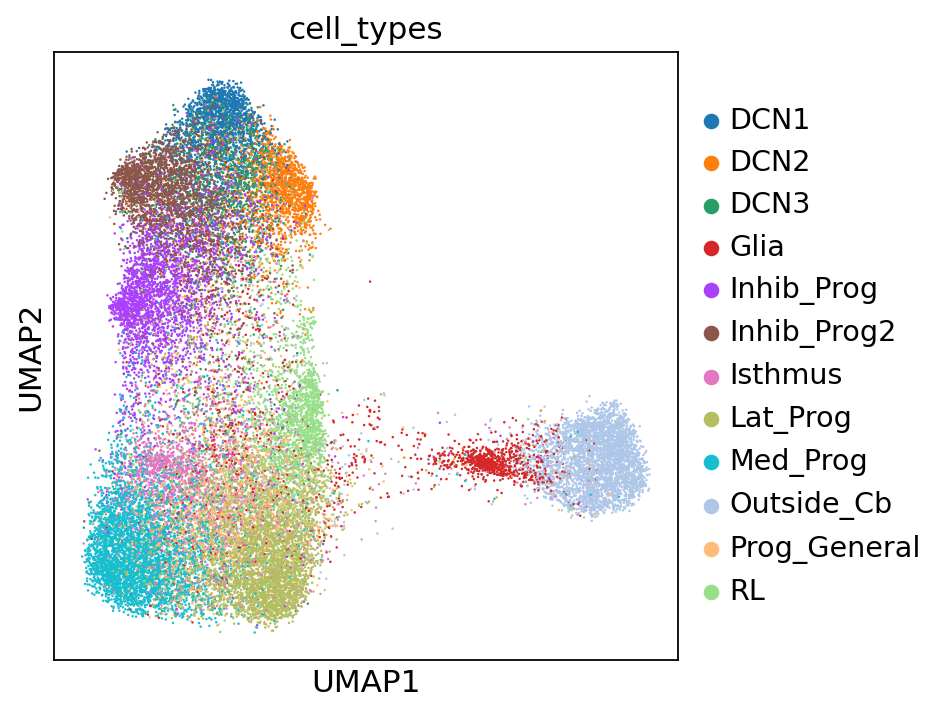

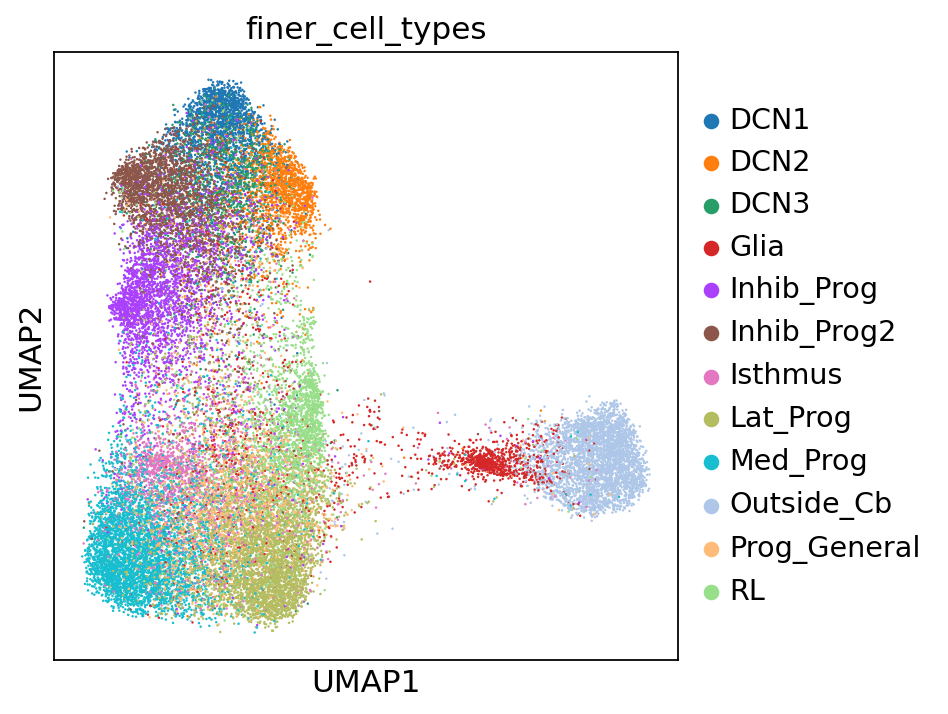

In [28]:
print("PCA")
sc.tl.pca(adata_all, svd_solver="arpack")

sc.external.pp.harmony_integrate(adata_all, 'library_id', theta = 15)
print("neighbors")
sc.pp.neighbors(adata_all,use_rep="X_pca_harmony")

print("UMAP")
sc.tl.umap(adata_all, min_dist = 0.01)

sc.set_figure_params(figsize = (5,5))

sc.pl.umap(adata_all, color = 'cell_types', size = 5)
sc.pl.umap(adata_all, color = 'finer_cell_types', size = 5)

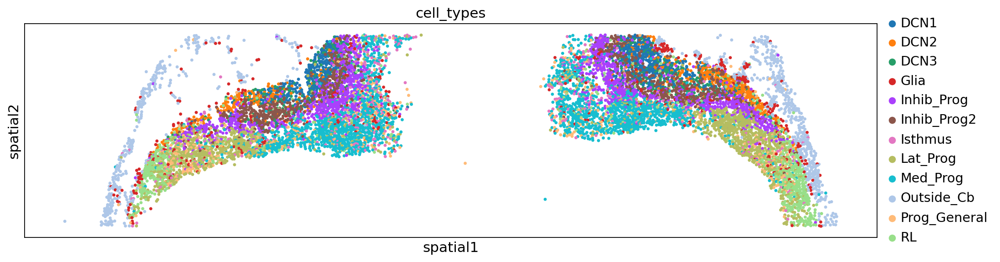

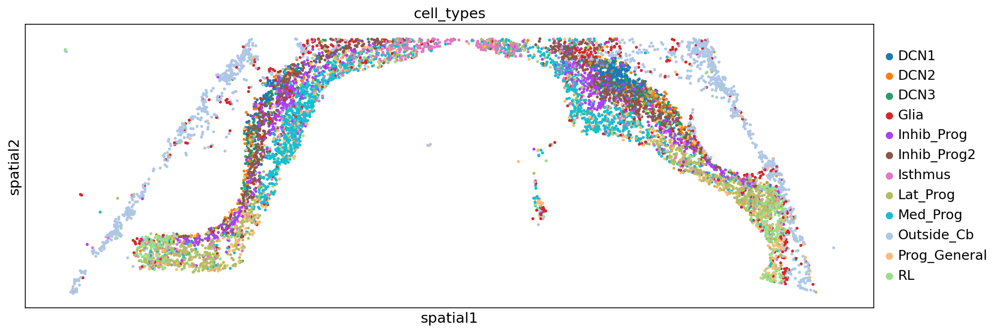

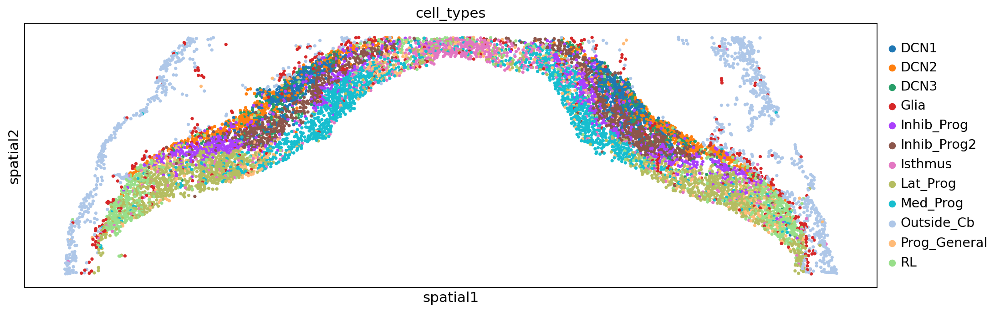

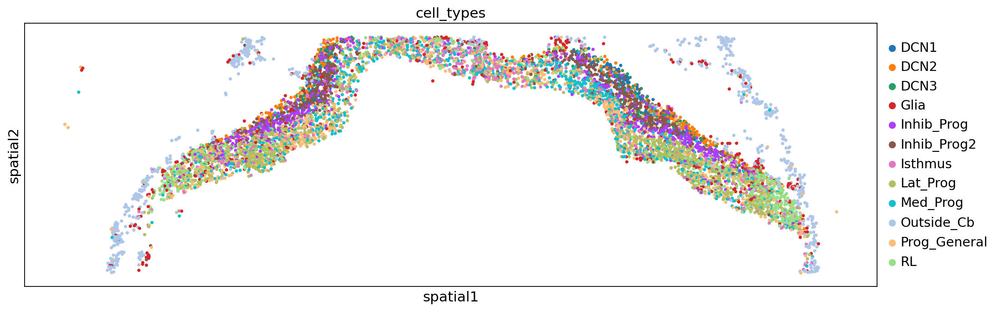

In [29]:
sc.set_figure_params(figsize = (25,25))

sc.set_figure_params(figsize=(15, 5))
for i in np.unique(adata_all.obs['library_id']):
    sc.pl.spatial(adata_all[adata_all.obs['library_id']==i], color='cell_types', spot_size = 70, vmax=2)
    #sc.pl.spatial(adata_crop[adata_crop.obs['library_id']==i], color='Robo2', spot_size = 70, vmax=2)
    #sc.pl.spatial(adata_crop[adata_crop.obs['library_id']==i], color='Ret', spot_size = 70, vmax=2)#

In [30]:
np.unique(adata_all.obs['cell_types'])

array(['DCN1', 'DCN2', 'DCN3', 'Glia', 'Inhib_Prog', 'Inhib_Prog2',
       'Isthmus', 'Lat_Prog', 'Med_Prog', 'Outside_Cb', 'Prog_General',
       'RL'], dtype=object)

In [31]:
inhibitory = ['Inhib_Prog', 'Inhib_Prog2','Isthmus', 'Lat_Prog', 'Med_Prog', 'Prog_General']

excitatory = ['DCN1', 'DCN2', 'DCN3', 'RL']

In [32]:
adata_exc = adata_all[adata_all.obs["finer_cell_types"].isin(excitatory)]
adata_inhib = adata_all[adata_all.obs["finer_cell_types"].isin(inhibitory)]

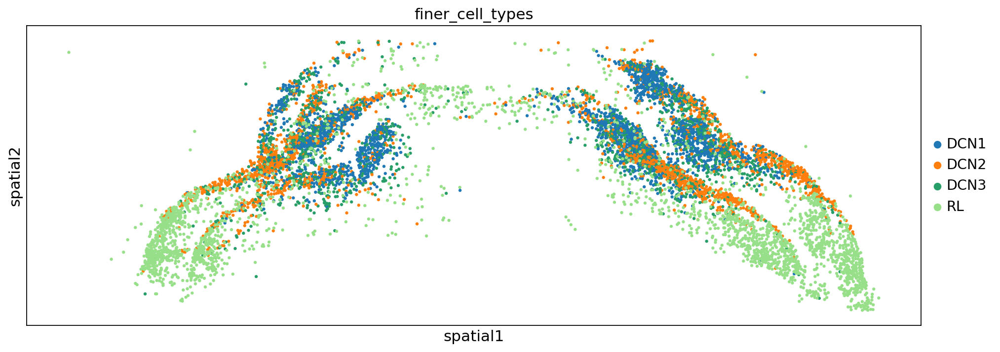

In [33]:
sc.pl.spatial(adata_exc, color='finer_cell_types', spot_size = 70)


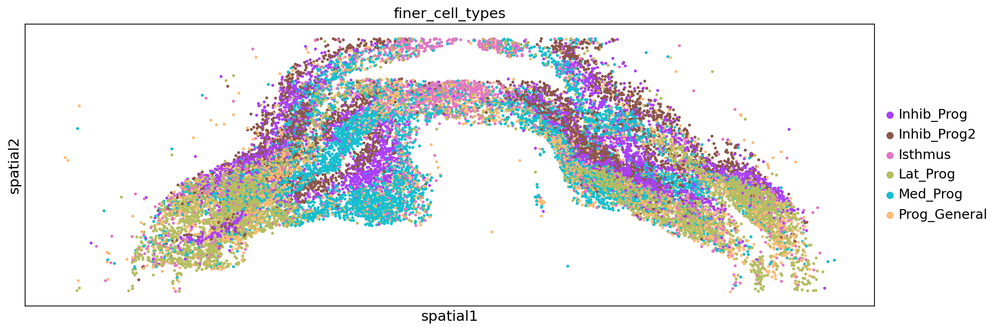

In [34]:
sc.pl.spatial(adata_inhib, color='finer_cell_types', spot_size = 70)


In [35]:
# 1) Define which cell types you want to keep

# 2) Create or copy a column called "excitatory"
adata_all.obs["excitatory"] = adata_all.obs["finer_cell_types"]
adata_all.obs["inhibitory"] = adata_all.obs["finer_cell_types"]

# 3) For any cell whose type is NOT in allowed_types, set that entry to NaN
mask = ~adata_all.obs["excitatory"].isin(excitatory)
adata_all.obs.loc[mask, "excitatory"] = np.nan

mask = ~adata_all.obs["inhibitory"].isin(inhibitory)
adata_all.obs.loc[mask, "inhibitory"] = np.nan


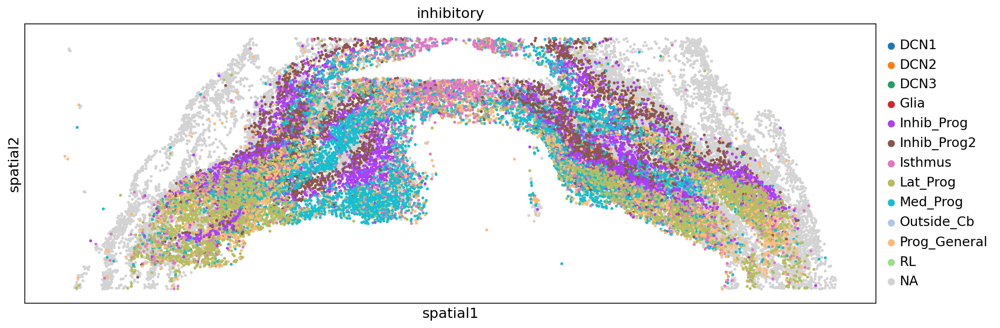

In [36]:
sc.pl.spatial(adata_all, color='inhibitory', spot_size = 70)


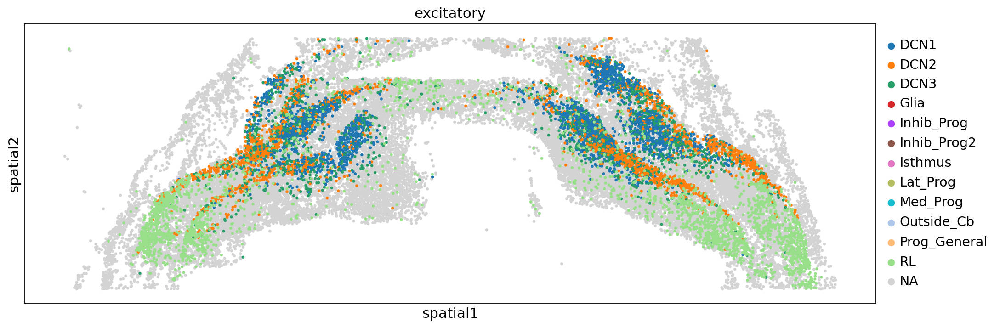

In [37]:
sc.pl.spatial(adata_all, color='excitatory', spot_size = 70)


In [41]:
adata_all.layers['lognorm']

array([[0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.57454145],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       ...,
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.37907836, 0.37907836, 0.        , ..., 0.        , 0.        ,
        0.        ],
       [0.        , 0.        , 0.        , ..., 0.        , 0.        ,
        0.        ]], dtype=float32)

In [42]:
adata_all.write_h5ad("adata_objects/e11_celltypes_spatialclustering.h5ad")